In [1]:
import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 
from rubin_scheduler.utils import angular_separation
from horseshoe_detailer import HorseshoeAvoidanceDetailer

import sqlite3
import pandas as pd
from os.path import basename

In [2]:
# use the detailer to load up the stellar catalog we are avoiding
hsd = HorseshoeAvoidanceDetailer()

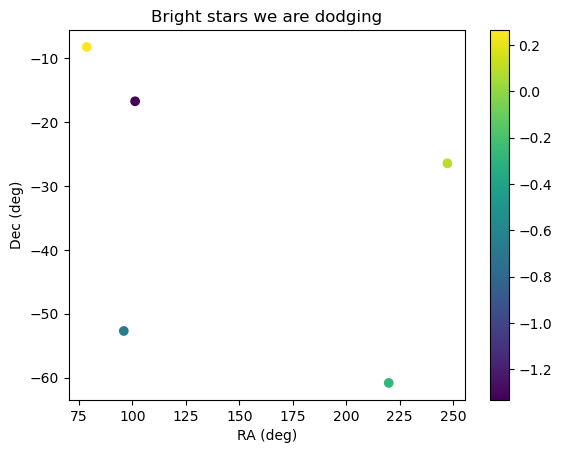

In [3]:
# Let's just pick one of the really bright ones
star_indx = np.where((hsd.star_mags["r"] < 0.5) & (hsd.star_dec_rad < 0))
plt.scatter(np.degrees(hsd.star_ra_rad[star_indx]), np.degrees(hsd.star_dec_rad[star_indx]), c=hsd.star_mags["r"][star_indx])
cb = plt.colorbar()
plt.title("Bright stars we are dodging")
plt.xlabel("RA (deg)")
plt.ylabel("Dec (deg)")
ras = np.degrees(hsd.star_ra_rad[star_indx][0:5])
decs = np.degrees(hsd.star_dec_rad[star_indx][0:5])

In [4]:
# Define a report element that we want to run. Needs branch maf-proto of rubin_sim to run
class HighResSpotElement(splat.BaseReportElement):
    def compute_elements(self,visits_df=None, visits_array=None, nside=1024, band="r", ra=0., dec=0., radius=10.):
        sl = splat.Slicer(nside=nside)
        distance = angular_separation(visits_array["fieldRA"], visits_array["fieldDec"], ra, dec)
        info = {"data_source": self.run_name}
        if band is None:
            info["observations_subset"] = self.subset + "\nDistance to point=%.2f deg" % radius
        else:
            info["observations_subset"] = self.subset + "\nband=%s\nDistance to point=%.2f deg" % (band, radius)

        metrics = []
        infos = []
        plot_dicts = []

        # Coadd depth
        #metrics.append(splat.CoaddM5Metric(band))
        #temp_info = copy.copy(info)
        #temp_info["group"] = "Basics"
        #temp_info["subgroup"] = "Coadd"
        #infos.append(temp_info)
        #plot_dicts.append({})

        # Number of visits
        metrics.append(splat.CountMetric())
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Counts"
        infos.append(temp_info)
        plot_dicts.append(
            {"log": True, "min": 1, "norm": "log", "cb_params": {"format": "%i", "n_ticks": 4}}
        )        
        if band is None:
            sub_data = visits_array[np.where(distance <= radius)[0]]
        else:
            sub_data = visits_array[np.where( (visits_array["band"] == band) & (distance <= radius))[0]]

        hp_arrays, infos = sl(sub_data, metrics, info=infos)

        return hp_arrays, infos, None

In [5]:
db_file = "baseline_v5.3.7_10yrs.db"
data_source = basename(db_file).replace('.db', '')
con = sqlite3.connect(db_file)
baseline_df = pd.read_sql('select * from observations;', con)
con.close()
# Convert to a numpy array
baseline_visits_array = baseline_df.to_records(index=False)

In [6]:
db_file = "horseshoe_radius_0_v5.3.7_10yrs.db"
data_source = basename(db_file).replace('.db', '')
con = sqlite3.connect(db_file)
horse_df = pd.read_sql('select * from observations;', con)
con.close()
# Convert to a numpy array
horse_visits_array = horse_df.to_records(index=False)

In [7]:
base_element = HighResSpotElement("baseline_v5.3.7_10yrs.db")
horse_element = HighResSpotElement("horseshoe_radius_0_v5.3.7_10yrs.db")

all_horse = []
all_base = []

all_ras = []
all_decs = []
all_bands = []

for ra,dec in zip(ras, decs):
    for band in ["u", "g", "r", "y", None]:
        horse_results = horse_element.compute_elements(visits_df=horse_df, visits_array=horse_visits_array,
                                                       nside=1024, band=band, ra=ra, dec=dec)
        all_horse.append(horse_results)
        base_results = base_element.compute_elements(visits_df=baseline_df, visits_array=baseline_visits_array,
                                                     nside=1024, band=band, ra=ra, dec=dec)
        all_base.append(base_results)
        all_ras.append(ra)
        all_decs.append(dec)
        all_bands.append(band)
        
                
        

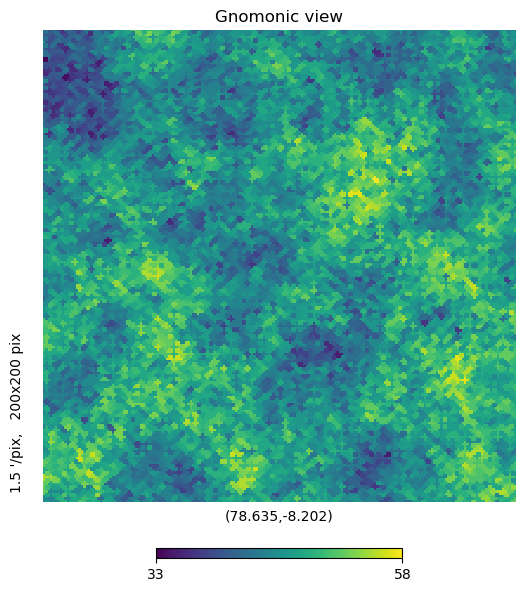

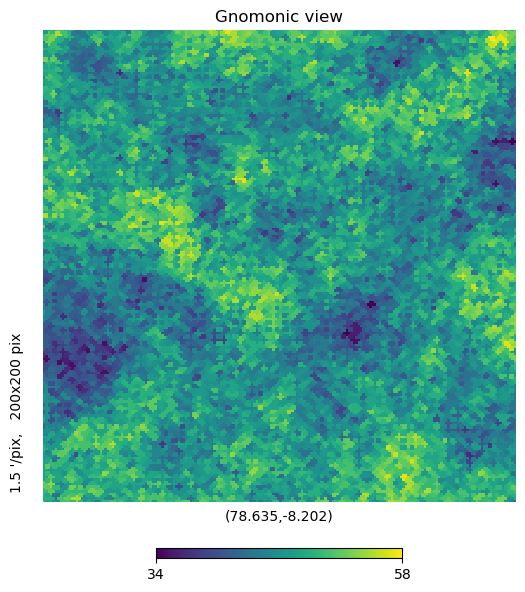

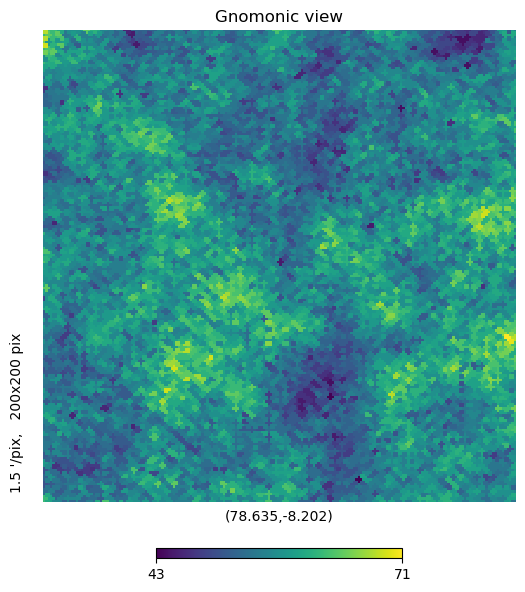

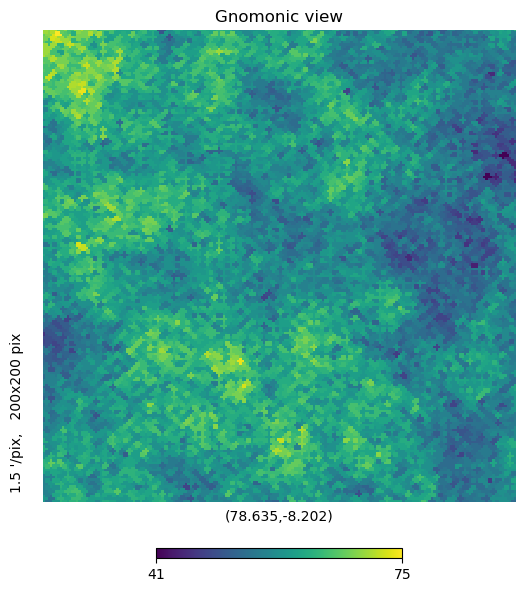

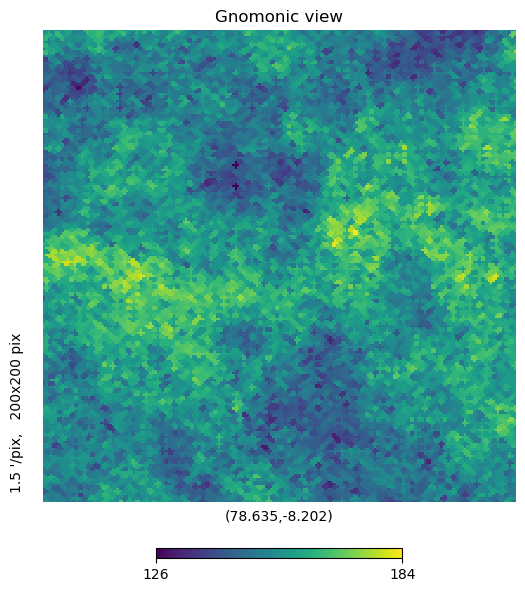

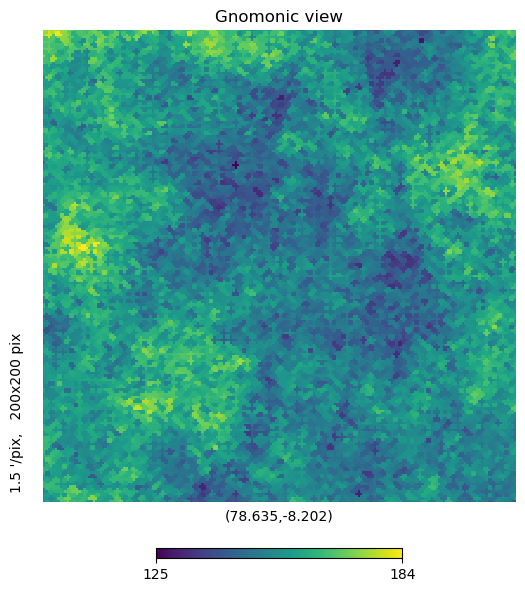

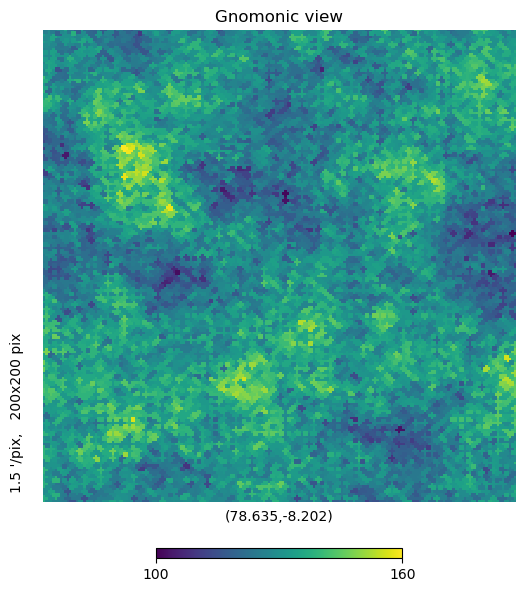

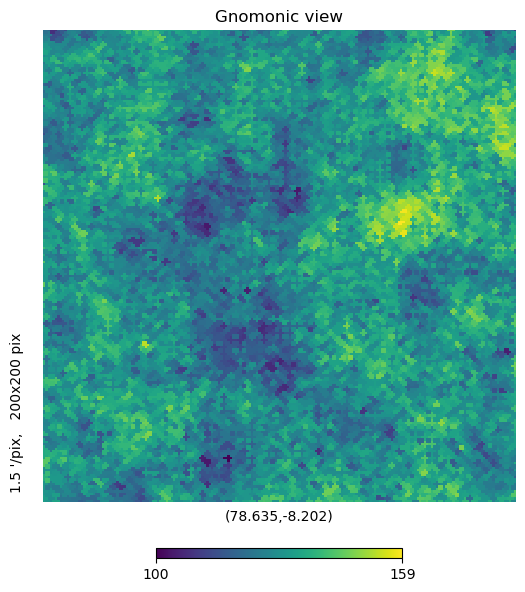

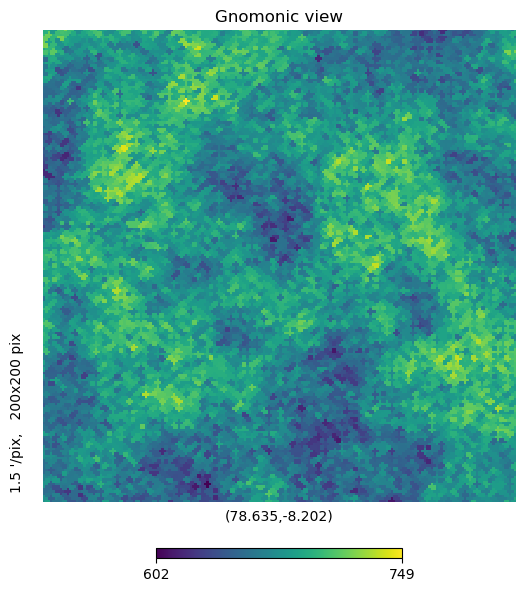

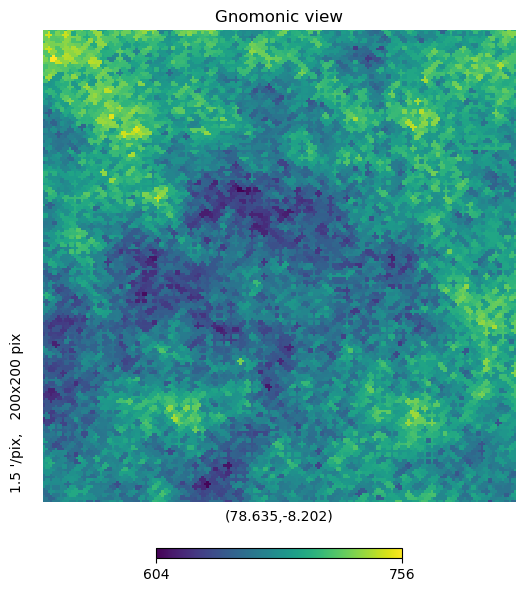

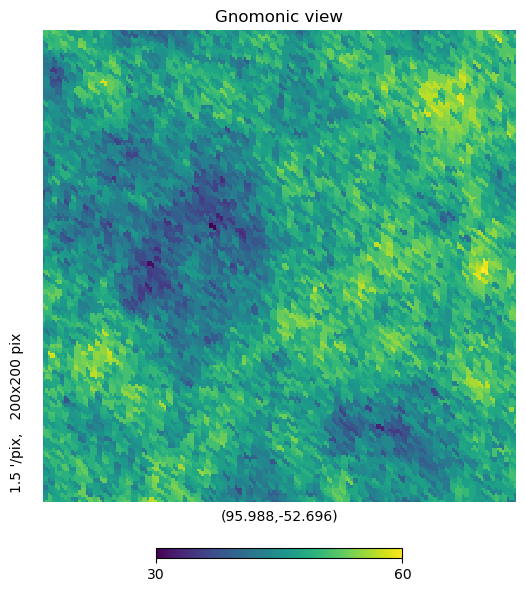

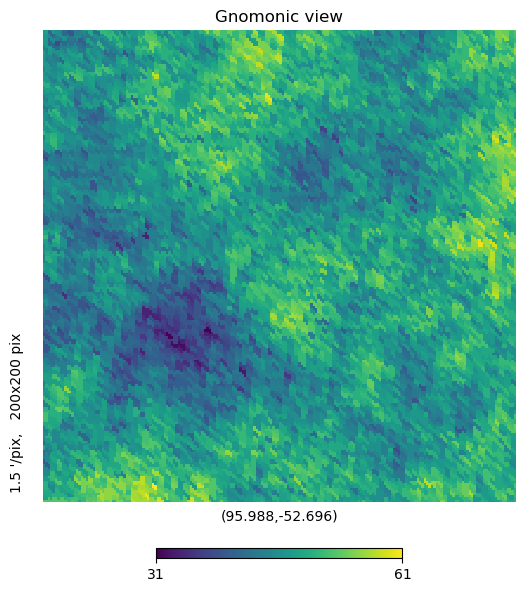

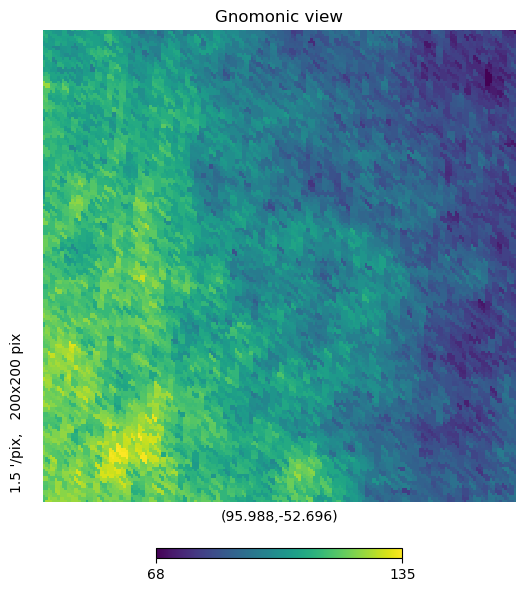

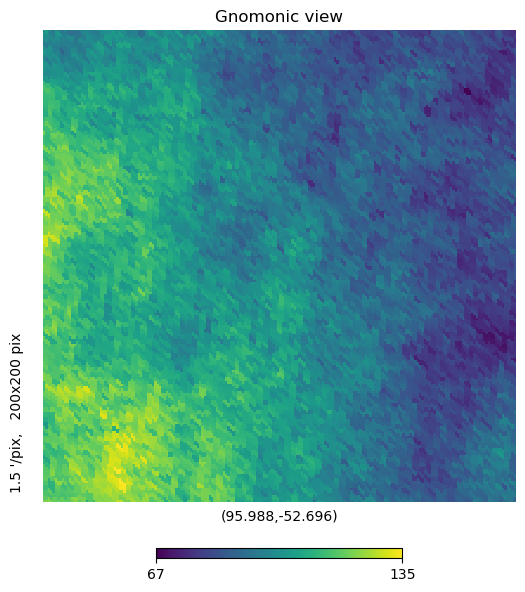

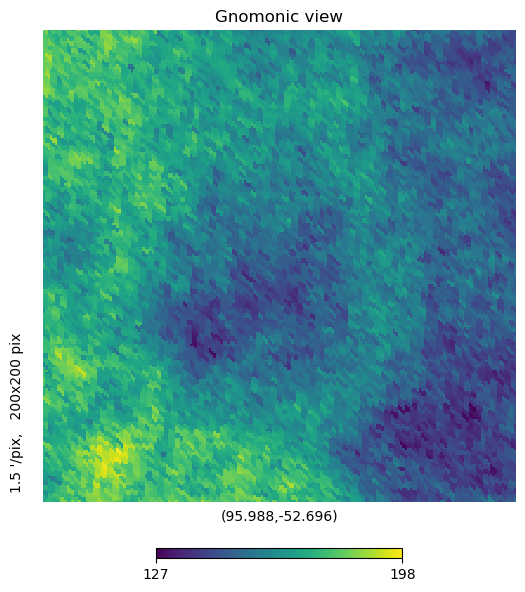

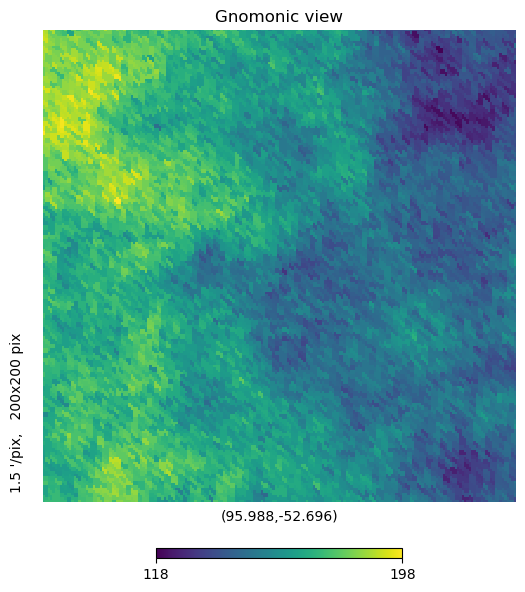

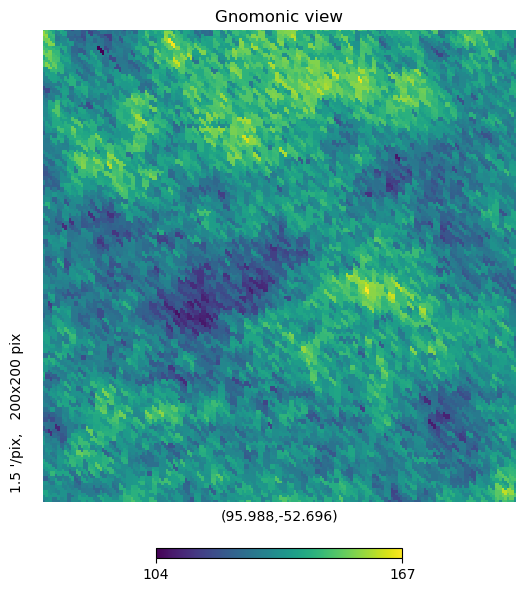

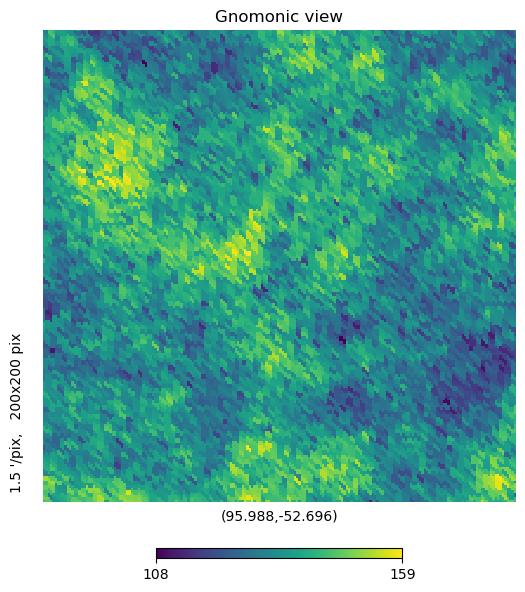

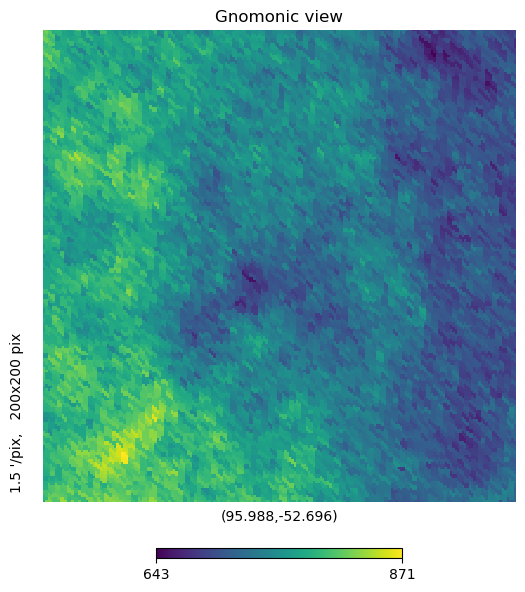

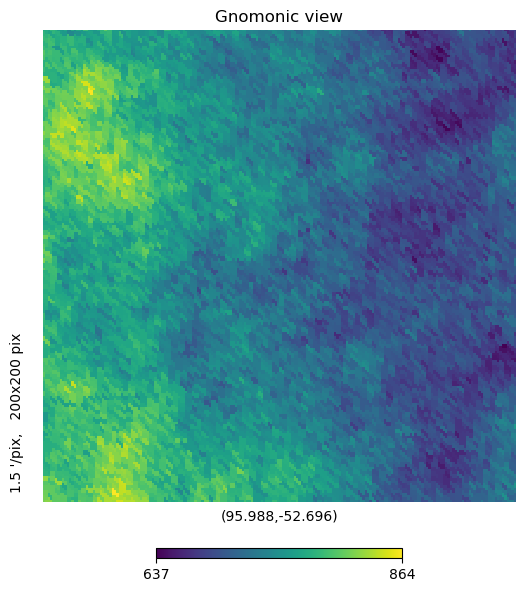

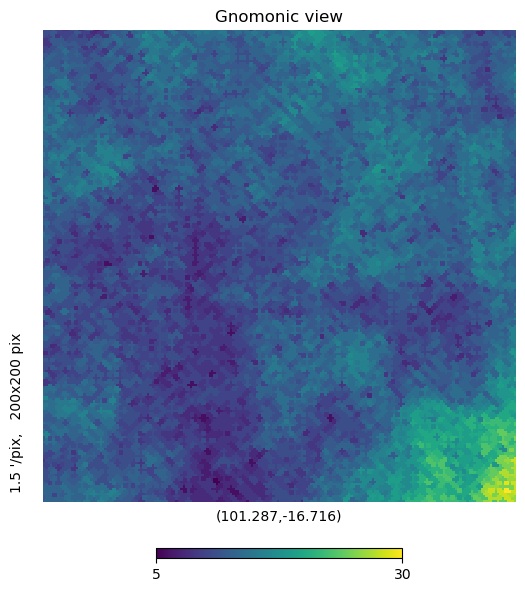

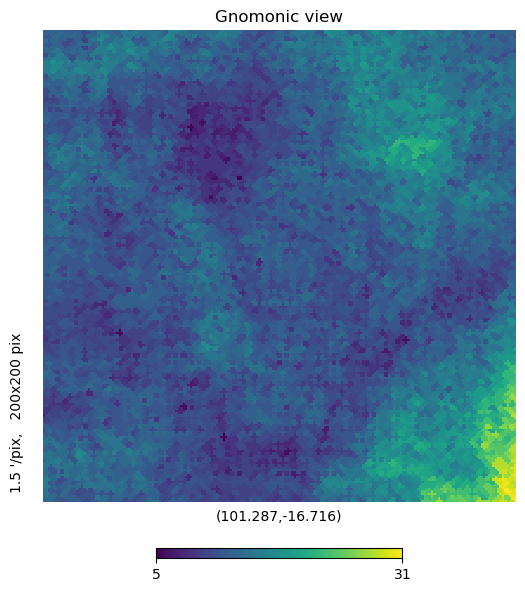

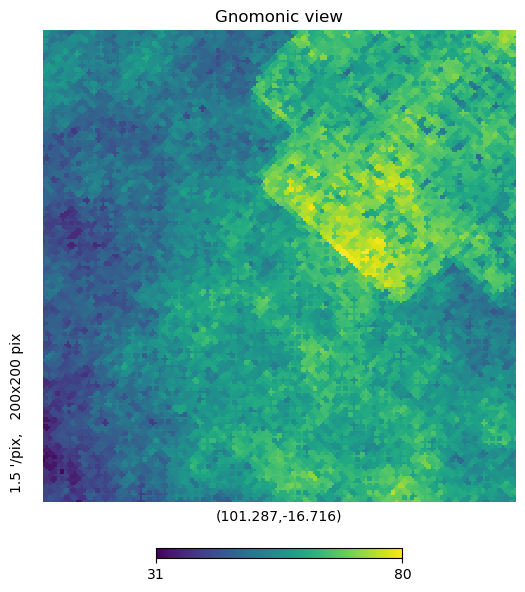

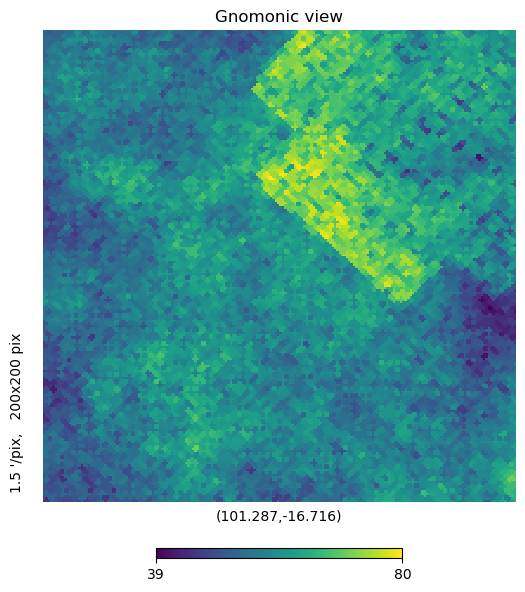

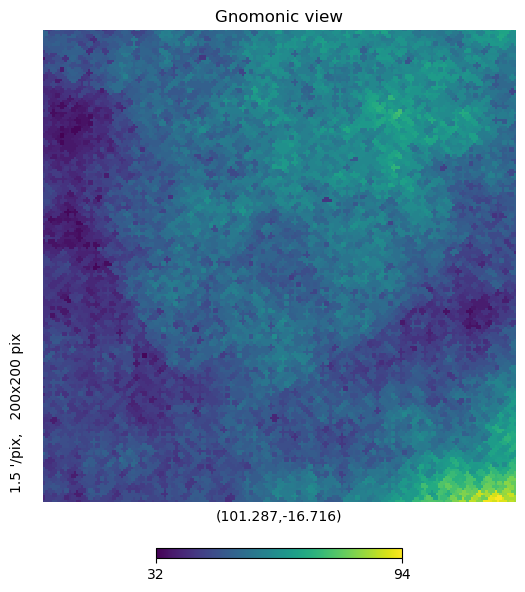

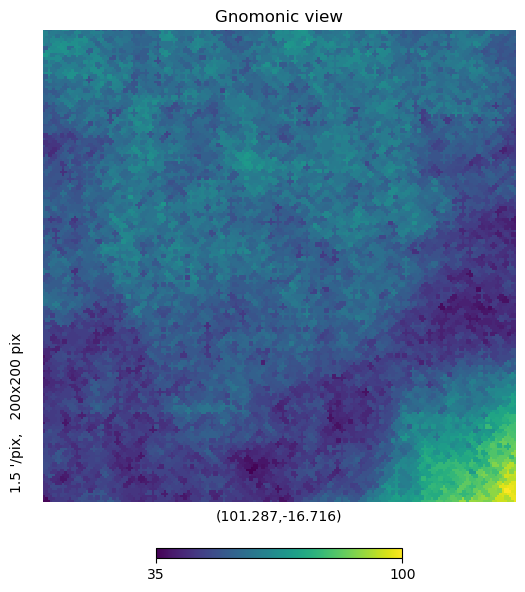

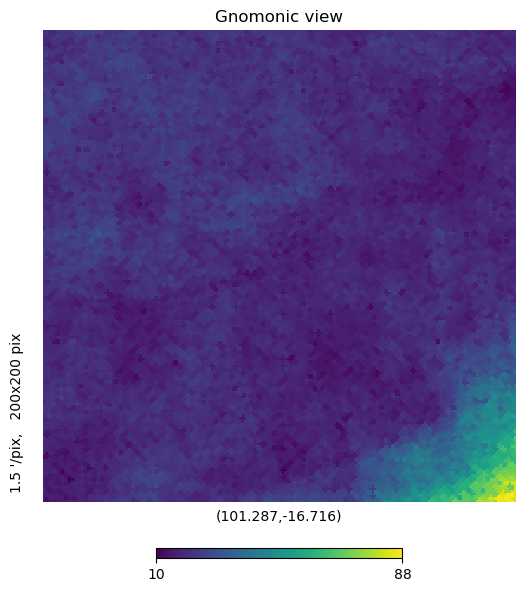

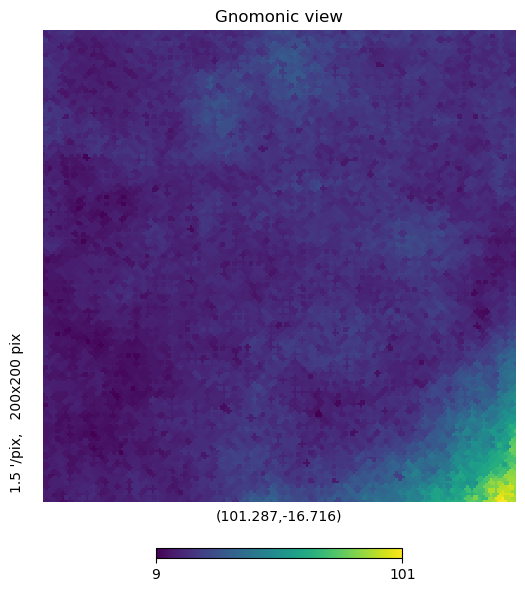

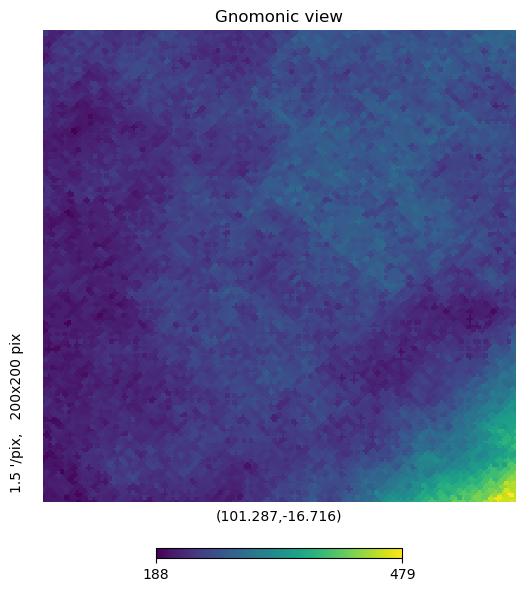

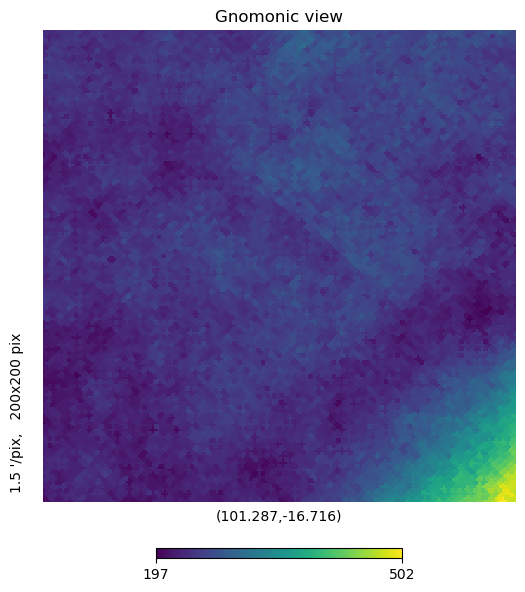

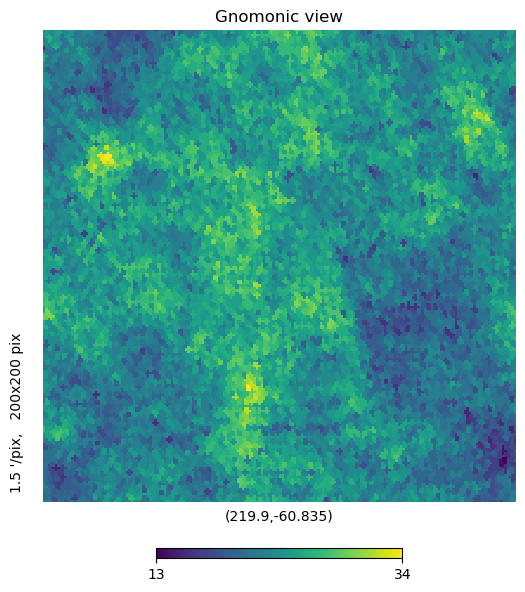

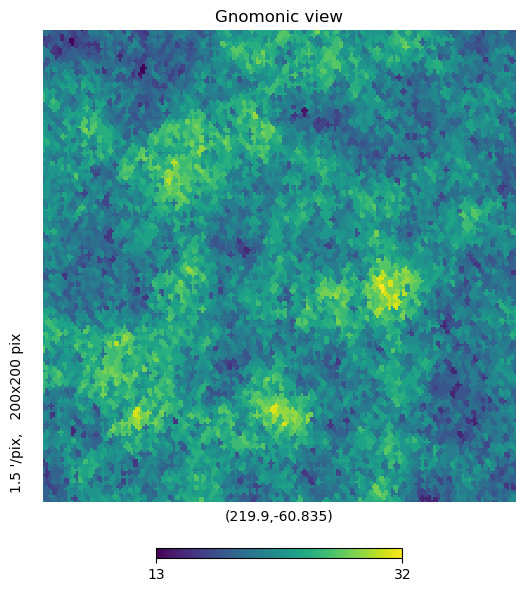

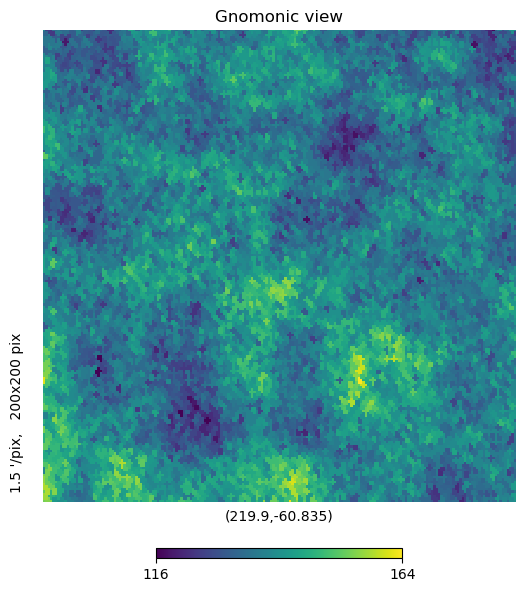

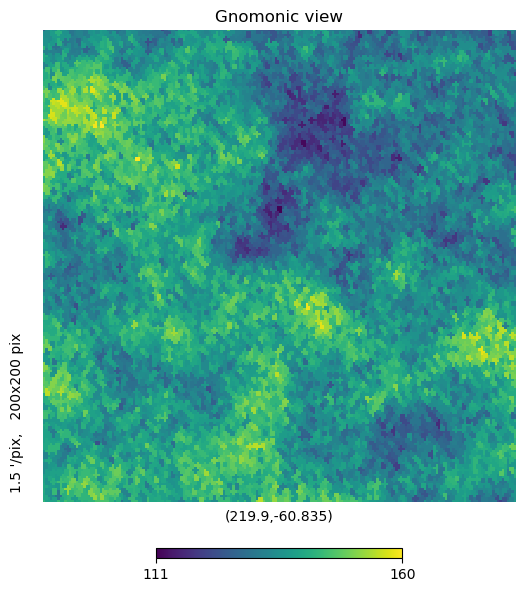

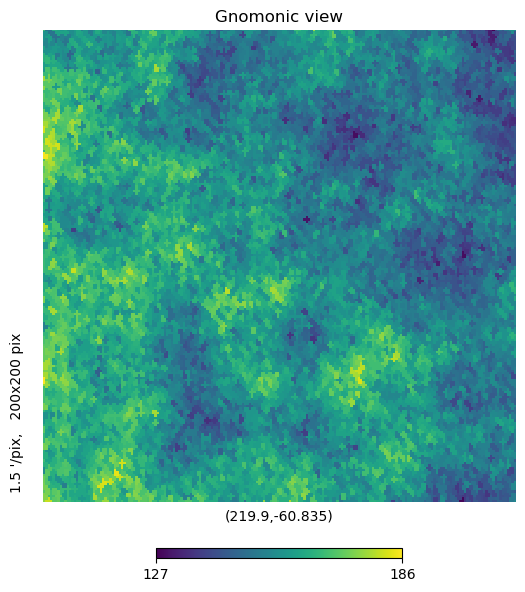

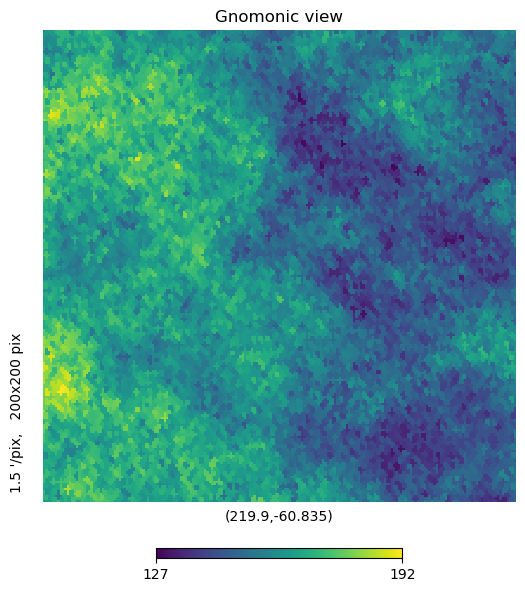

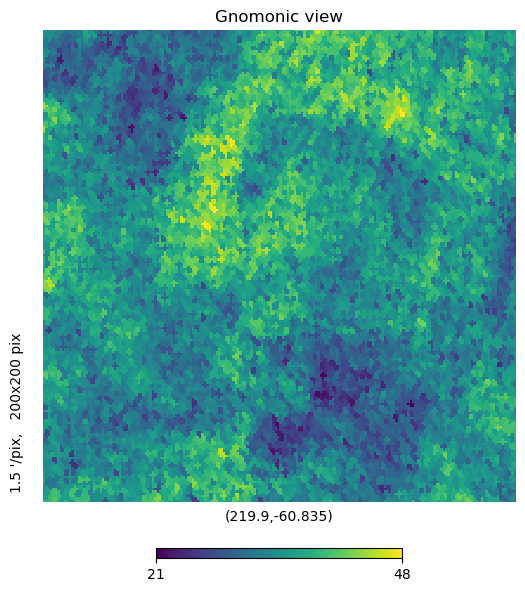

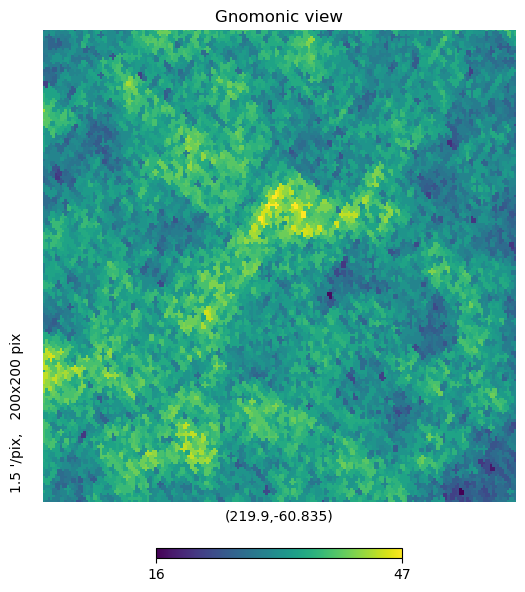

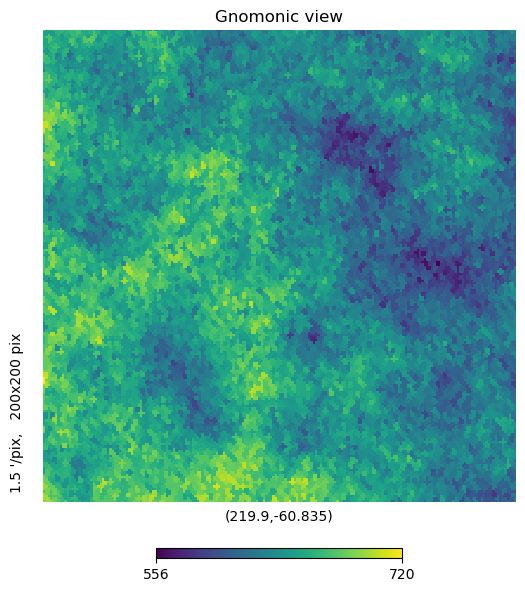

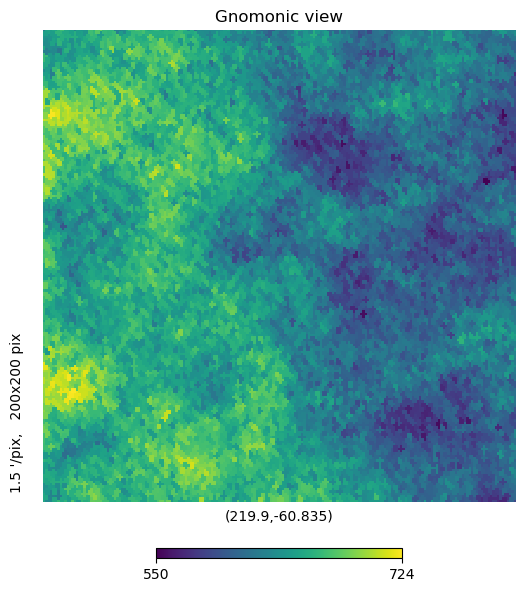

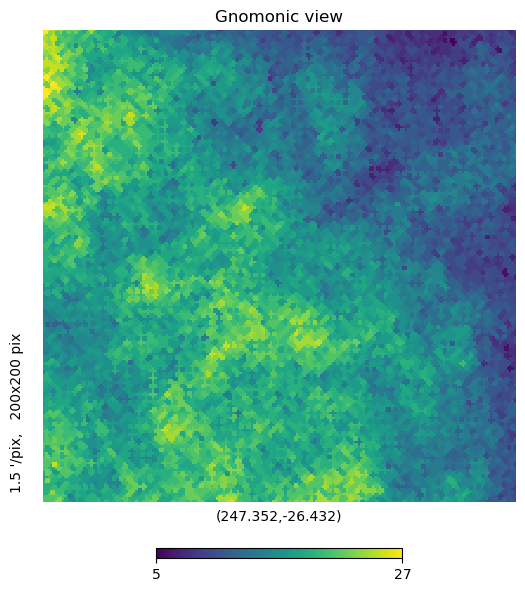

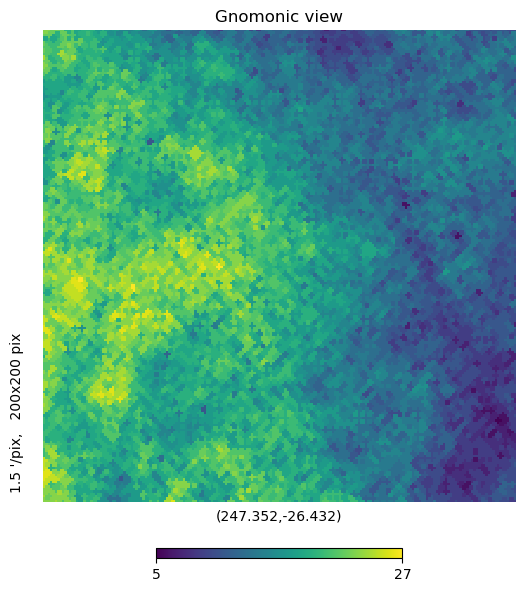

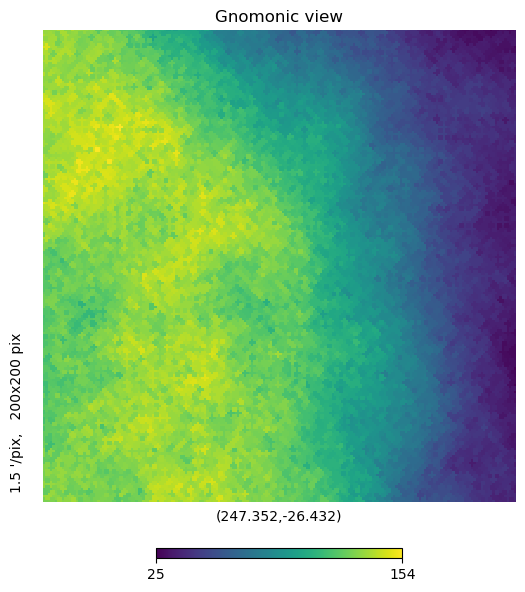

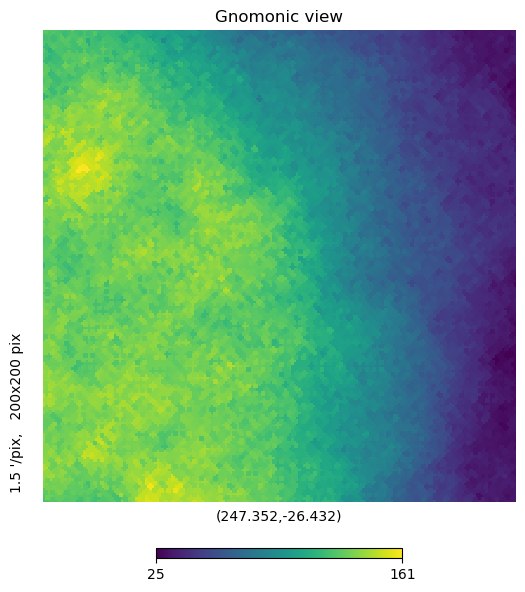

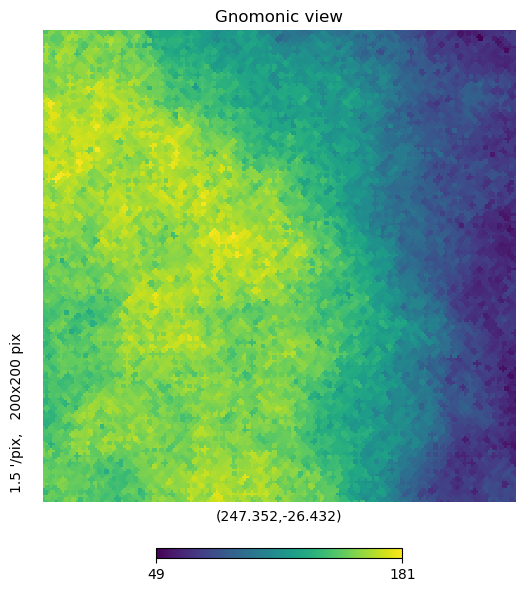

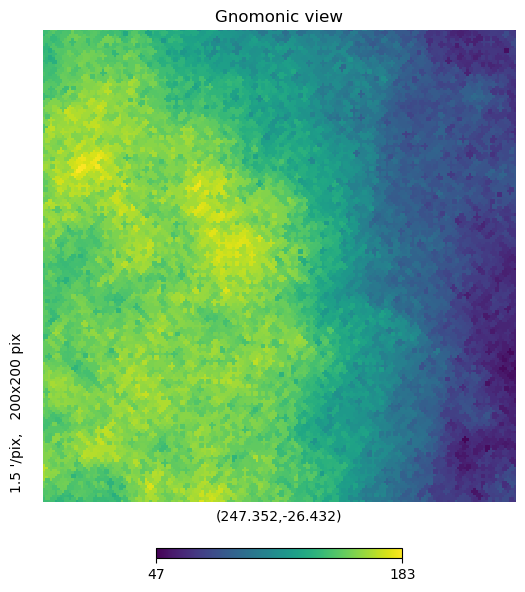

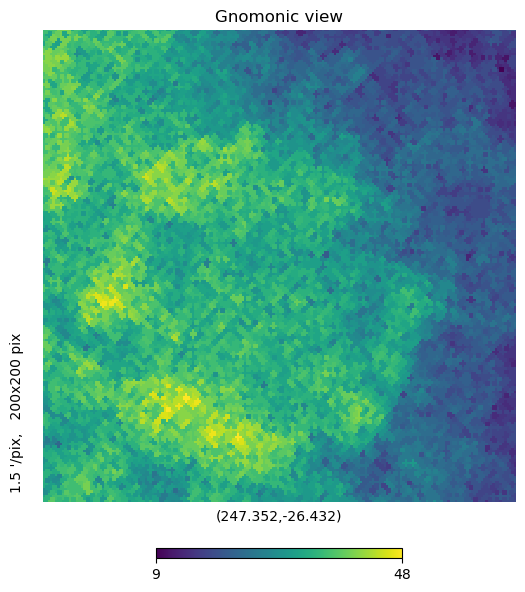

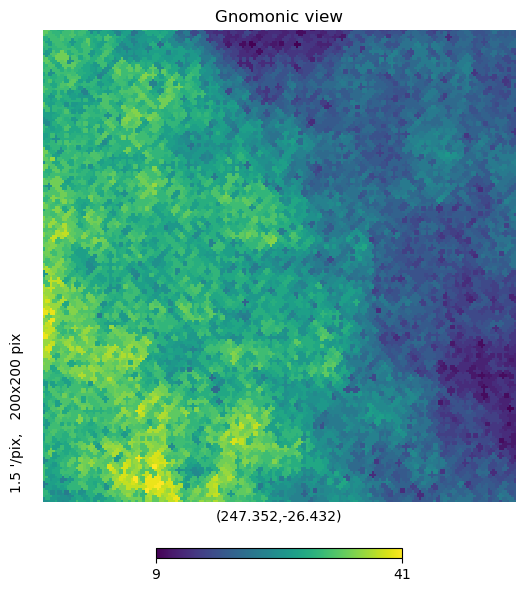

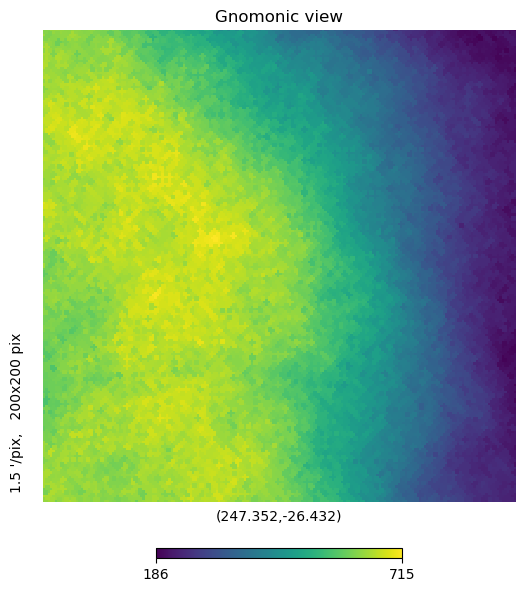

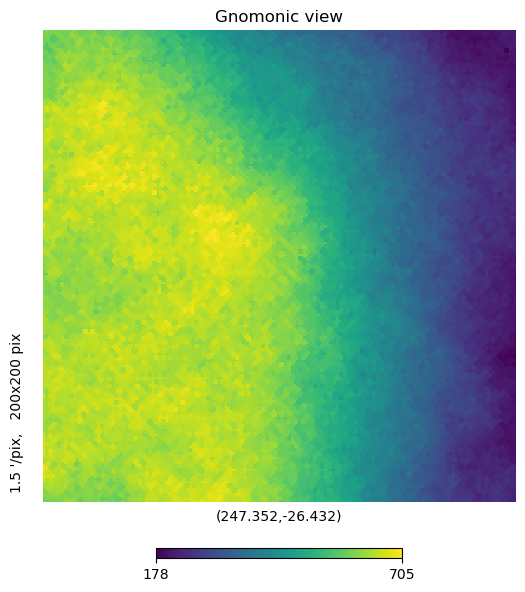

In [8]:
for ah, ab, ra, dec, band in zip(all_horse, all_base, all_ras, all_decs, all_bands):
    hp.gnomview(ah[0], rot=(ra,dec))
    hp.gnomview(ab[0], rot=(ra,dec))